In [88]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
GRAINE = 42
np.random.seed(GRAINE)
Path('data/raw').mkdir(parents=True, exist_ok=True)

def charger(serie):
    url = f'https://fred.stlouisfed.org/graph/fredgraph.csv?id={serie}'
    df = pd.read_csv(url)
    df.to_csv(f'data/raw/{serie}.csv', index=False)
    df.columns = ['date', serie]
    df['date'] = pd.to_datetime(df['date'])
    return df.set_index('date')[serie]

chomage = charger('UNRATE')   # mensuel
pib = charger('GDPC1')        # trimestriel
print(chomage.tail(3)); print(pib.tail(3))
print('Valeurs manquantes :', chomage.isna().sum(), pib.isna().sum())

date
2026-08-01    4.1
2026-09-01    4.2
2026-10-01    4.1
Name: UNRATE, dtype: float64
date
2026-01-01    24274.383
2026-04-01    24408.011
2026-07-01    24611.077
Name: GDPC1, dtype: float64
Valeurs manquantes : 1 0


Le mois d'octobre 2025 manque dans UNRATE. Je n'ai donc pas calculé la moyenne des trimestres incomplets : 2025 T4 est exclu, et 2026 T1 aussi, car sa variation aurait couvert deux trimestres. La croissance et la variation sont calculées avec le trimestre précédent uniquement, donc sans utiliser l'avenir.

In [89]:
# 1) Quel mois manque ?
print('Mois manquant :', chomage[chomage.isna()].index.strftime('%Y-%m').tolist())

# 2) Chômage trimestriel = moyenne des 3 mois, seulement si les 3 mois sont présents
nb_mois = chomage.resample('QS').count()
u = chomage.resample('QS').mean()[nb_mois == 3]

# 3) Table trimestrielle : on garde tous les trimestres du PIB avant de calculer les variations
df = pd.concat([u.rename('u'), pib.rename('pib')], axis=1)
df['g'] = 100 * (df['pib'] / df['pib'].shift(1) - 1)   # croissance du PIB (%), passé seulement
df['du'] = df['u'] - df['u'].shift(1)                   # variation du chômage (points)
df = df.dropna()

print(len(df), 'trimestres, de', df.index.min().date(), 'à', df.index.max().date())
print(df[['g', 'du']].describe().round(2))

Mois manquant : ['2025-10']
312 trimestres, de 1948-04-01 à 2026-07-01
            g      du
count  312.00  312.00
mean     0.78    0.00
std      1.11    0.69
min     -7.88   -4.20
25%      0.32   -0.20
50%      0.77   -0.07
75%      1.20    0.13
max      7.76    9.17


Trimestres atypiques :
               g    du
date                  
1958-01-01 -2.60  1.37
2020-04-01 -7.88  9.17
2020-07-01  7.76 -4.20
Corrélation g / du : -0.753


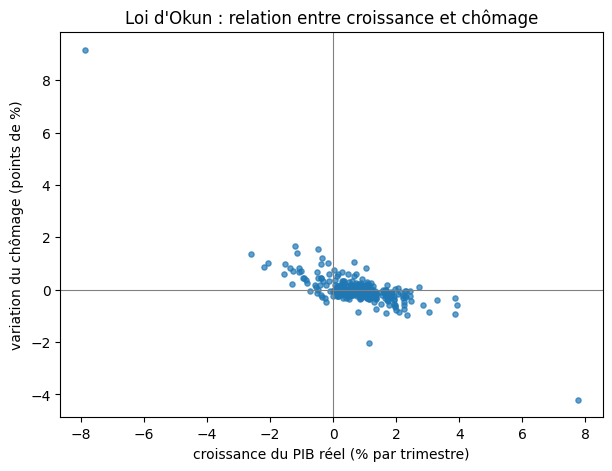

In [90]:
# Valeurs atypiques : z-score > 3 en valeur absolue (on les garde, ce sont des chocs réels)
z = (df[['g', 'du']] - df[['g', 'du']].mean()) / df[['g', 'du']].std()
print('Trimestres atypiques :'); print(df.loc[(z.abs() > 3).any(axis=1), ['g', 'du']].round(2))
print('Corrélation g / du :', round(df['g'].corr(df['du']), 3))

# Graphique : relation entre croissance et variation du chômage
plt.figure(figsize=(7, 5))
plt.scatter(df['g'], df['du'], s=14, alpha=.7)
plt.axhline(0, color='gray', lw=.8); plt.axvline(0, color='gray', lw=.8)
plt.xlabel('croissance du PIB réel (% par trimestre)')
plt.ylabel('variation du chômage (points de %)')
plt.title("Loi d'Okun : relation entre croissance et chômage")
plt.show()

**Découpage train / test.** J'ai coupé en 2010 pour garder environ 20 % des données en test, en respectant l'ordre chronologique. Le test couvre la période après la crise de 2008 et le choc de 2020.

In [91]:
coupure = pd.Timestamp('2010-01-01')
train = df[df.index < coupure]
test  = df[df.index >= coupure]

print('Train :', len(train), 'trimestres,', train.index.min().date(), '->', train.index.max().date())
print('Test  :', len(test),  'trimestres,', test.index.min().date(),  '->', test.index.max().date())
print('Part du test :', round(len(test) / len(df) * 100, 1), '%')

Train : 247 trimestres, 1948-04-01 -> 2009-10-01
Test  : 65 trimestres, 2010-01-01 -> 2026-07-01
Part du test : 20.8 %


In [92]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error

X_train, y_train = train[['g']], train['du']
tscv = TimeSeriesSplit(n_splits=5)

mae = {'Moyenne du train': [], 'Dernière valeur': [], 'Régression linéaire': []}
for i_app, i_val in tscv.split(X_train):
    y_app, y_val = y_train.iloc[i_app], y_train.iloc[i_val]
    mae['Moyenne du train'].append(mean_absolute_error(y_val, [y_app.mean()] * len(y_val)))
    prec = y_train.shift(1).iloc[i_val]
    mae['Dernière valeur'].append(mean_absolute_error(y_val, prec))
    modele = LinearRegression().fit(X_train.iloc[i_app], y_app)
    mae['Régression linéaire'].append(mean_absolute_error(y_val, modele.predict(X_train.iloc[i_val])))

print('MAE moyenne en validation croisée (5 plis) :')
for nom, valeurs in mae.items():
    print(f'  {nom:22s} {np.mean(valeurs):.3f}')

MAE moyenne en validation croisée (5 plis) :
  Moyenne du train       0.252
  Dernière valeur        0.218
  Régression linéaire    0.196


In [93]:
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error, r2_score

modele = LinearRegression().fit(train[['g']], train['du'])
y_test = test['du']
pred = modele.predict(test[['g']])
pred_moy = [train['du'].mean()] * len(test)
pred_prec = df['du'].shift(1).loc[test.index]

def metriques(y, p):
    return [mean_absolute_error(y, p), np.sqrt(mean_squared_error(y, p)), r2_score(y, p)]

tab = pd.DataFrame({'Moyenne du train': metriques(y_test, pred_moy),
                    'Dernière valeur': metriques(y_test, pred_prec),
                    'Régression linéaire': metriques(y_test, pred)},
                   index=['MAE', 'RMSE', 'R²']).T.round(3)
print(tab)

ols = sm.OLS(train['du'], sm.add_constant(train['g'])).fit()
print(pd.concat([ols.params.rename('coef'), ols.conf_int().rename(columns={0: 'IC 2,5 %', 1: 'IC 97,5 %'})], axis=1).round(3))

                       MAE   RMSE     R²
Moyenne du train     0.425  1.302 -0.008
Dernière valeur      0.545  2.031 -1.452
Régression linéaire  0.404  0.949  0.465
        coef  IC 2,5 %  IC 97,5 %
const  0.263     0.217      0.308
g     -0.291    -0.326     -0.256


Plus grosses erreurs (test) :
               g  du réel  du prédit  erreur
date                                        
2020-04-01 -7.88     9.17       2.56    6.61
2020-07-01  7.76    -4.20      -2.00   -2.20
2020-10-01  1.13    -2.03      -0.07   -1.97
2021-07-01  0.78    -0.87       0.04   -0.90
2011-01-01 -0.24    -0.47       0.33   -0.80


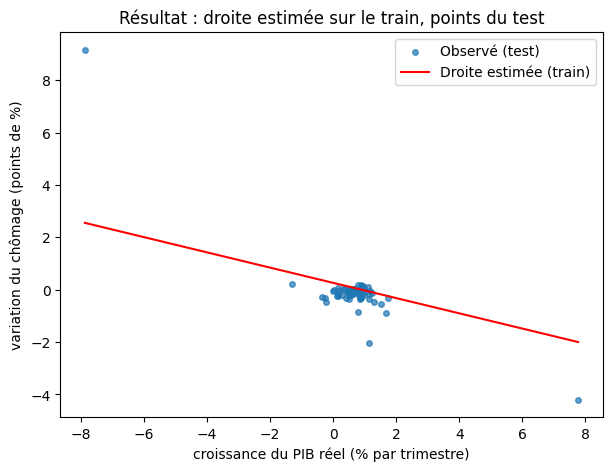

In [94]:
# Les 5 plus grosses erreurs sur le test
erreurs = y_test - pred
tab_err = pd.DataFrame({'g': test['g'], 'du réel': y_test, 'du prédit': pred, 'erreur': erreurs}).round(2)
print('Plus grosses erreurs (test) :')
print(tab_err.loc[erreurs.abs().nlargest(5).index])

# Figure : points observés du test et droite estimée
plt.figure(figsize=(7, 5))
plt.scatter(test['g'], y_test, s=16, alpha=.7, label='Observé (test)')
gg = np.linspace(test['g'].min(), test['g'].max(), 100)
plt.plot(gg, modele.predict(pd.DataFrame({'g': gg})), color='red', label='Droite estimée (train)')
plt.xlabel('croissance du PIB réel (% par trimestre)')
plt.ylabel('variation du chômage (points de %)')
plt.title('Résultat : droite estimée sur le train, points du test')
plt.legend(); plt.show()

In [95]:
# Test de sensibilité : on retire 2020 T2 et T3 du test (les deux chocs extrêmes)
exclus = pd.to_datetime(['2020-04-01', '2020-07-01'])
test_s = test.drop(exclus)
pred_s = modele.predict(test_s[['g']])
pred_moy_s = [train['du'].mean()] * len(test_s)
pred_prec_s = df['du'].shift(1).loc[test_s.index]

tab_s = pd.DataFrame({'Moyenne du train': metriques(test_s['du'], pred_moy_s),
                      'Dernière valeur': metriques(test_s['du'], pred_prec_s),
                      'Régression linéaire': metriques(test_s['du'], pred_s)},
                     index=['MAE', 'RMSE', 'R²']).T.round(3)
print('Test sans 2020 T2 et T3 :')
print(tab_s)

Test sans 2020 T2 et T3 :
                       MAE   RMSE     R²
Moyenne du train     0.226  0.373 -0.383
Dernière valeur      0.208  0.389 -0.511
Régression linéaire  0.277  0.397 -0.571


In [96]:
# Stabilité : on refait la régression sur 3 sous-périodes (2020 T2 et T3 exclus)
periodes = {'1948-1983': ('1948', '1983'), '1984-2009': ('1984', '2009'), '2010-2026': ('2010', '2026')}
lignes = []
for nom, (a, b) in periodes.items():
    d = df.loc[a:b].drop(exclus, errors='ignore')
    m = LinearRegression().fit(d[['g']], d['du'])
    lignes.append([nom, len(d), m.intercept_, m.coef_[0], d['g'].mean(), d['du'].mean()])
print(pd.DataFrame(lignes, columns=['période', 'n', 'const', 'pente', 'g moyen', 'du moyen']).round(3).to_string(index=False))

  période   n  const  pente  g moyen  du moyen
1948-1983 143  0.290 -0.288    0.891     0.034
1984-2009 104  0.244 -0.322    0.715     0.013
2010-2026  63 -0.059 -0.176    0.639    -0.171


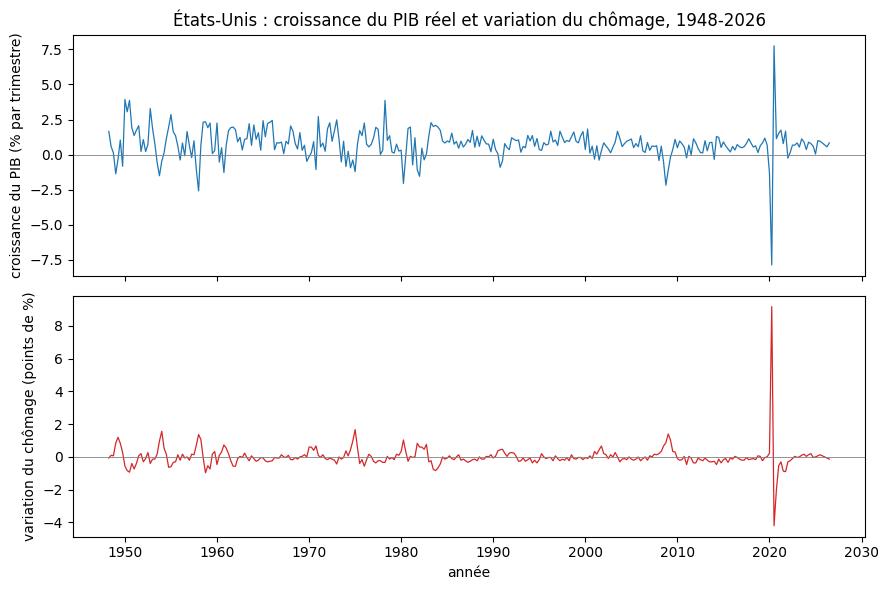

In [97]:
Path('figures').mkdir(exist_ok=True)
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(df.index, df['g'], color='tab:blue', lw=.9)
ax[0].set_ylabel('croissance du PIB (% par trimestre)')
ax[0].set_title('États-Unis : croissance du PIB réel et variation du chômage, 1948-2026')
ax[1].plot(df.index, df['du'], color='tab:red', lw=.9)
ax[1].set_ylabel('variation du chômage (points de %)')
ax[1].set_xlabel('année')
for a in ax:
    a.axhline(0, color='gray', lw=.6)
plt.tight_layout()
plt.savefig('figures/g1_series.png', dpi=150)
plt.show()

**Interprétation.** Les deux séries évoluent en miroir : quand la croissance chute (1958, 1975, 1982, 2009), le chômage monte au même moment. Hors récessions, la variation du chômage reste proche de 0. Le choc de 2020 (−7,9 % de PIB, +9,2 points de chômage) écrase l'échelle. Les variations paraissent plus fortes avant 1985 qu'après.

In [98]:
from sklearn.linear_model import Ridge

def mae_cv(modele_cv):
    scores = []
    for i_app, i_val in tscv.split(X_train):
        m = modele_cv.fit(X_train.iloc[i_app], y_train.iloc[i_app])
        scores.append(mean_absolute_error(y_train.iloc[i_val], m.predict(X_train.iloc[i_val])))
    return np.mean(scores)

print('Régression linéaire (avec constante) : MAE CV =', round(mae_cv(LinearRegression()), 3))
print('Régression linéaire (sans constante) : MAE CV =', round(mae_cv(LinearRegression(fit_intercept=False)), 3))
for alpha in [0.01, 0.1, 1, 10, 100]:
    print(f'Ridge alpha={alpha:<6} : MAE CV =', round(mae_cv(Ridge(alpha=alpha)), 3))

Régression linéaire (avec constante) : MAE CV = 0.196
Régression linéaire (sans constante) : MAE CV = 0.222
Ridge alpha=0.01   : MAE CV = 0.196
Ridge alpha=0.1    : MAE CV = 0.196
Ridge alpha=1      : MAE CV = 0.195
Ridge alpha=10     : MAE CV = 0.194
Ridge alpha=100    : MAE CV = 0.203


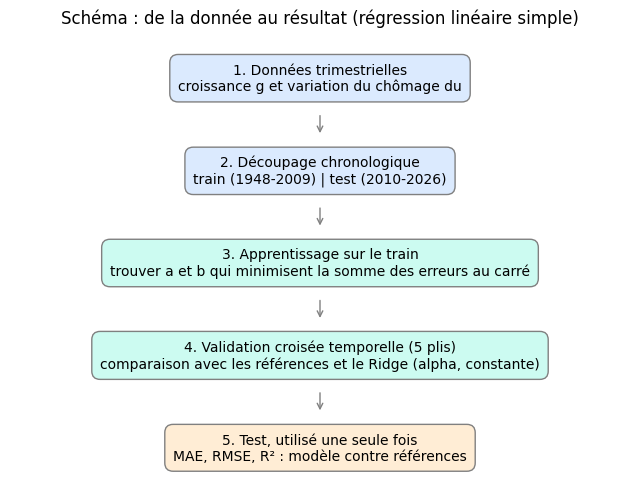

In [99]:
fig, ax = plt.subplots(figsize=(8, 6)); ax.axis('off')
etapes = ["1. Données trimestrielles\ncroissance g et variation du chômage du",
          "2. Découpage chronologique\ntrain (1948-2009) | test (2010-2026)",
          "3. Apprentissage sur le train\ntrouver a et b qui minimisent la somme des erreurs au carré",
          "4. Validation croisée temporelle (5 plis)\ncomparaison avec les références et le Ridge (alpha, constante)",
          "5. Test, utilisé une seule fois\nMAE, RMSE, R² : modèle contre références"]
couleurs = ['#dbeafe', '#dbeafe', '#ccfbf1', '#ccfbf1', '#ffedd5']
for i, (t, c) in enumerate(zip(etapes, couleurs)):
    y = 0.9 - i * 0.2
    ax.text(0.5, y, t, ha='center', va='center', fontsize=10, transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.6', fc=c, ec='gray'))
    if i < len(etapes) - 1:
        ax.annotate('', xy=(0.5, y - 0.125), xytext=(0.5, y - 0.075), xycoords='axes fraction',
                    arrowprops=dict(arrowstyle='->', color='gray'))
ax.set_title('Schéma : de la donnée au résultat (régression linéaire simple)')
plt.savefig('figures/g4_schema.png', dpi=150, bbox_inches='tight')
plt.show()